# 01 — Statistiques descriptives du jeu de données Adult

**Objectif du projet** : prédire si une personne gagne plus de 50 000 $ par an à partir de
ses caractéristiques socio-démographiques (recensement américain de 1994).

**Objectif de ce notebook** : comprendre les données avant de modéliser :
1. qualité des données (types, valeurs manquantes, doublons) ;
2. distribution de la variable cible ;
3. distribution de chaque variable et lien avec la cible ;
4. relations entre variables (corrélations) ;
5. décisions de preprocessing qui en découlent.

> Prérequis : `adult.data` et `adult.test` dans `data/raw/` (voir le README).

In [1]:
import sys
from pathlib import Path

# Permet d'importer le package src depuis le dossier notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Enregistre la figure dans reports/figures/ pour la présentation."""
    fig.savefig(FIGURES_DIR / name, dpi=120, bbox_inches="tight")

In [2]:
from src.config import CATEGORICAL_FEATURES, NUMERIC_FEATURES, SKEWED_FEATURES
from src.data.load_data import load_train_test, split_X_y
from src.data.eda import cramers_v_matrix, missing_report, target_rate_by

train, test = load_train_test()
X, y = split_X_y(train)
NUM = NUMERIC_FEATURES + SKEWED_FEATURES + ["fnlwgt"]
CAT = CATEGORICAL_FEATURES + ["education"]
print(f"Train : {train.shape[0]} lignes x {train.shape[1]} colonnes")
print(f"Test  : {test.shape[0]} lignes")

Train : 32561 lignes x 15 colonnes
Test  : 16281 lignes


## 1. Aperçu et qualité des données

L'EDA est réalisée **uniquement sur le jeu d'entraînement** : le jeu de test est réservé
à l'évaluation finale, pour ne pas biaiser nos choix.

In [3]:
train.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [5]:
train[NUM].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.6,13.6,17.0,28.0,37.0,48.0,90.0
education-num,32561.0,10.1,2.6,1.0,9.0,10.0,12.0,16.0
hours-per-week,32561.0,40.4,12.3,1.0,40.0,40.0,45.0,99.0
capital-gain,32561.0,1077.6,7385.3,0.0,0.0,0.0,0.0,99999.0
capital-loss,32561.0,87.3,403.0,0.0,0.0,0.0,0.0,4356.0
fnlwgt,32561.0,189778.4,105550.0,12285.0,117827.0,178356.0,237051.0,1484705.0


In [6]:
print("Valeurs manquantes (codées '?' dans les fichiers bruts) :")
display(missing_report(train).round(2))
print(f"Lignes avec au moins une valeur manquante : {train.isna().any(axis=1).mean():.1%}")
print(f"Lignes dupliquées : {train.duplicated().sum()}")

Valeurs manquantes (codées '?' dans les fichiers bruts) :


,n_manquants,pct_manquants
occupation,1843,5.66
workclass,1836,5.64
native-country,583,1.79


Lignes avec au moins une valeur manquante : 7.4%
Lignes dupliquées : 24


**À retenir**
- Les valeurs manquantes ne concernent que 3 variables catégorielles : `workclass`,
  `occupation` et `native-country`. Elles touchent une petite part des lignes.
- `workclass` et `occupation` sont souvent manquantes **ensemble** (vérifiable ci-dessous) :
  probablement des personnes hors emploi.
- On choisit d'**imputer** (modalité la plus fréquente) plutôt que de supprimer ces lignes,
  pour ne pas perdre d'information. L'imputation est faite dans le pipeline (pas de fuite).
- Les doublons sont plausibles dans un recensement (deux personnes au profil identique) :
  on les conserve.

In [7]:
pd.crosstab(train["workclass"].isna(), train["occupation"].isna(),
            rownames=["workclass manquant"], colnames=["occupation manquant"])

occupation manquant,False,True
workclass manquant,,
False,30718,7
True,0,1836


## 2. La variable cible : `income`

,effectif,pourcentage
income,,
<=50K,24720,75.9
>50K,7841,24.1


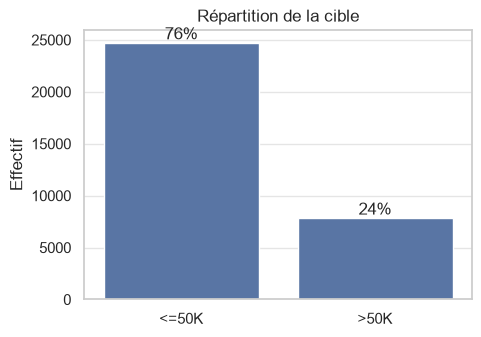

In [8]:
counts = train["income"].value_counts()
display(pd.DataFrame({"effectif": counts, "pourcentage": (100 * counts / len(train)).round(1)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=train, x="income", order=["<=50K", ">50K"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v / len(train):.0%}" for v in c.datavalues])
ax.set(title="Répartition de la cible", xlabel="", ylabel="Effectif")
save(fig, "eda_target.png")

**À retenir : les classes sont déséquilibrées** (environ 3 personnes sur 4 gagnent moins de 50K).

Conséquences pour la modélisation :
- l'**accuracy est trompeuse** : un modèle qui répond toujours `<=50K` aurait déjà ~76 % ;
- on suivra donc **ROC-AUC**, **PR-AUC** et **F1** (sur la classe `>50K`) ;
- on utilisera une **validation croisée stratifiée** (même proportion de classes dans chaque pli) ;
- un modèle de référence (*baseline*) servira de point de comparaison.

## 3. Variables numériques

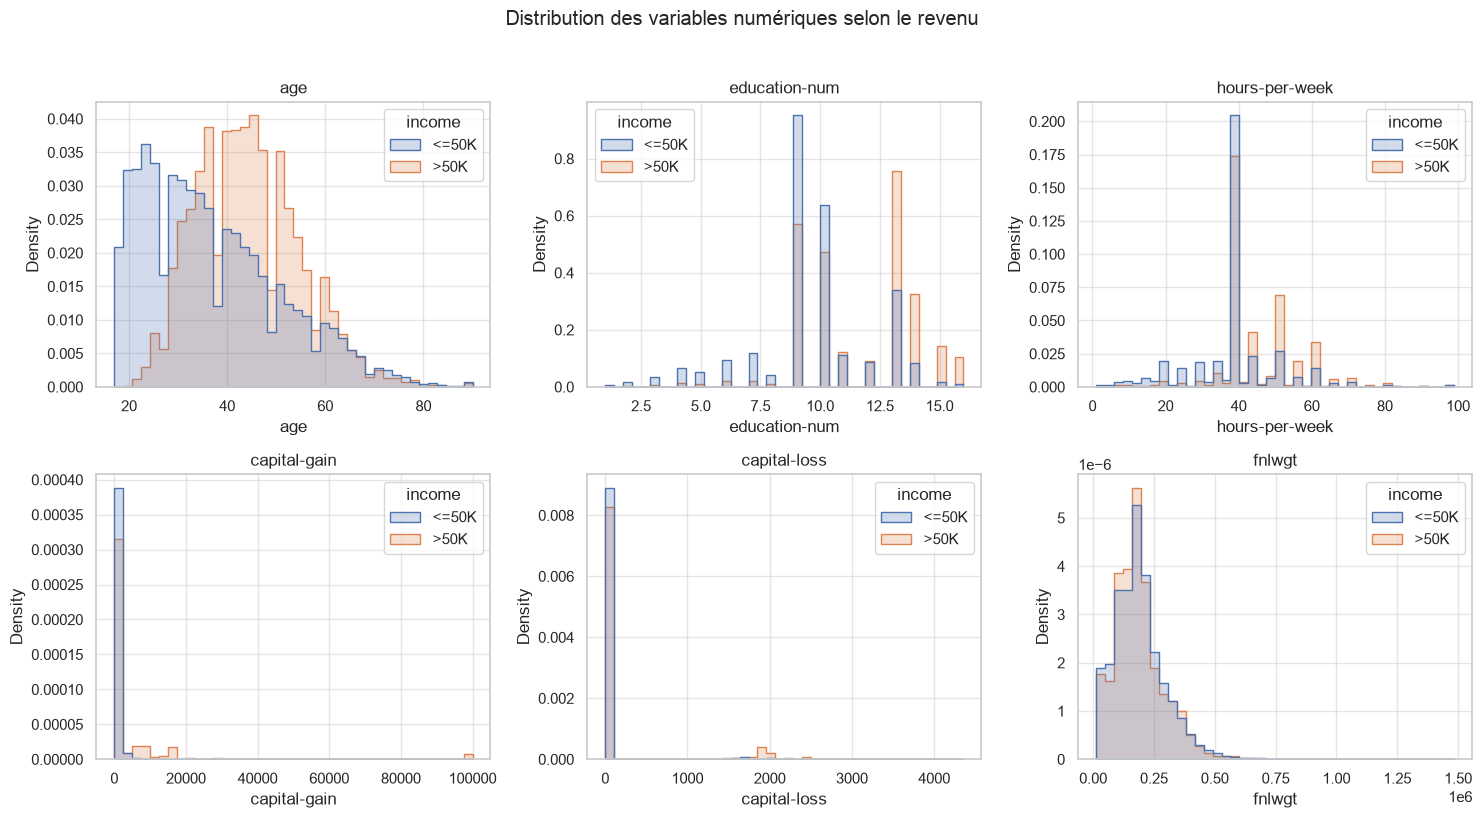

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_FEATURES + SKEWED_FEATURES + ["fnlwgt"]):
    sns.histplot(data=train, x=col, hue="income", bins=40, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(col)
fig.suptitle("Distribution des variables numériques selon le revenu", y=1.02)
fig.tight_layout()
save(fig, "eda_numeric_hist.png")

income,médiane <=50K,médiane >50K
age,34.0,44.0
education-num,9.0,12.0
hours-per-week,40.0,40.0


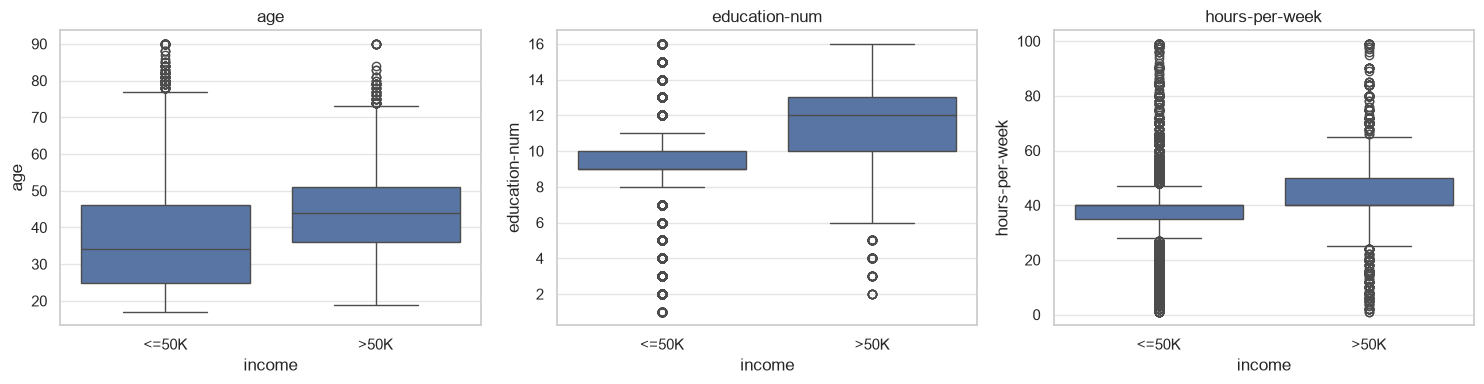

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=train, x="income", y=col, order=["<=50K", ">50K"], ax=ax)
    ax.set_title(col)
fig.tight_layout()
save(fig, "eda_numeric_box.png")

display(train.groupby("income")[NUMERIC_FEATURES].median().T.rename(columns=lambda c: f"médiane {c}"))

In [11]:
for col in SKEWED_FEATURES:
    share_zero = (train[col] == 0).mean()
    print(f"{col:13s} : {share_zero:.1%} de zéros, max = {train[col].max():,}")
print("\nTaux de >50K selon que capital-gain est nul ou non :")
display(target_rate_by(train.assign(a_gain=train["capital-gain"] > 0), "a_gain", y).round(1))

capital-gain  : 91.7% de zéros, max = 99,999
capital-loss  : 95.3% de zéros, max = 4,356

Taux de >50K selon que capital-gain est nul ou non :


,effectif,taux_50k
a_gain,,
True,2712,61.8
False,29849,20.7


**À retenir** (vérifier sur vos sorties)
- `age` : les personnes à >50K sont nettement plus âgées en moyenne ; la relation n'est pas
  linéaire (le revenu monte puis redescend après 60 ans) → avantage aux modèles non linéaires.
- `education-num` et `hours-per-week` : plus élevés chez les >50K.
- `capital-gain` / `capital-loss` : presque toujours nuls, avec quelques valeurs extrêmes
  (99 999 = valeur plafond) → **transformation log(1+x)** dans le preprocessing.
  Avoir un gain en capital est fortement associé au revenu >50K.
- `fnlwgt` : distributions quasi identiques selon le revenu. C'est un **poids de sondage**,
  pas une caractéristique de la personne → **variable supprimée**.

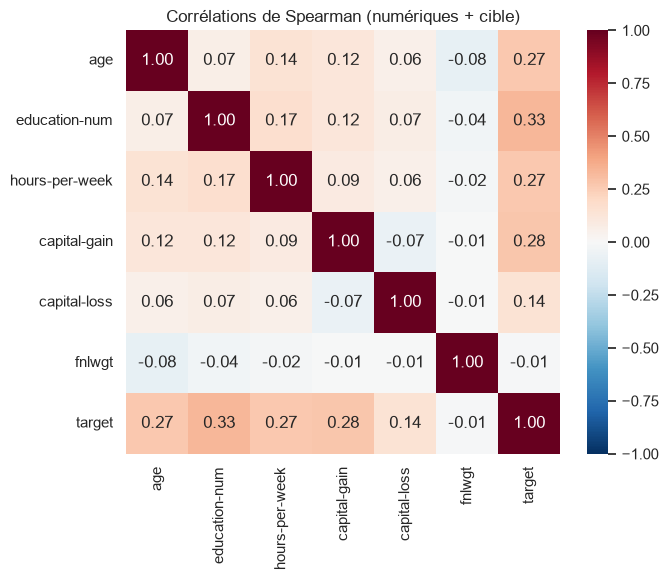

In [12]:
corr = train[NUM].assign(target=y).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations de Spearman (numériques + cible)")
save(fig, "eda_corr_numeric.png")

On utilise Spearman (corrélation de rangs) car les variables sont asymétriques.
Les variables numériques sont **peu corrélées entre elles** : pas de redondance forte.

## 4. Variables catégorielles

In [13]:
for col in CATEGORICAL_FEATURES:
    print(f"{col} : {train[col].nunique()} modalités")

workclass : 8 modalités
marital-status : 7 modalités
occupation : 14 modalités
relationship : 6 modalités
race : 5 modalités
sex : 2 modalités
native-country : 41 modalités


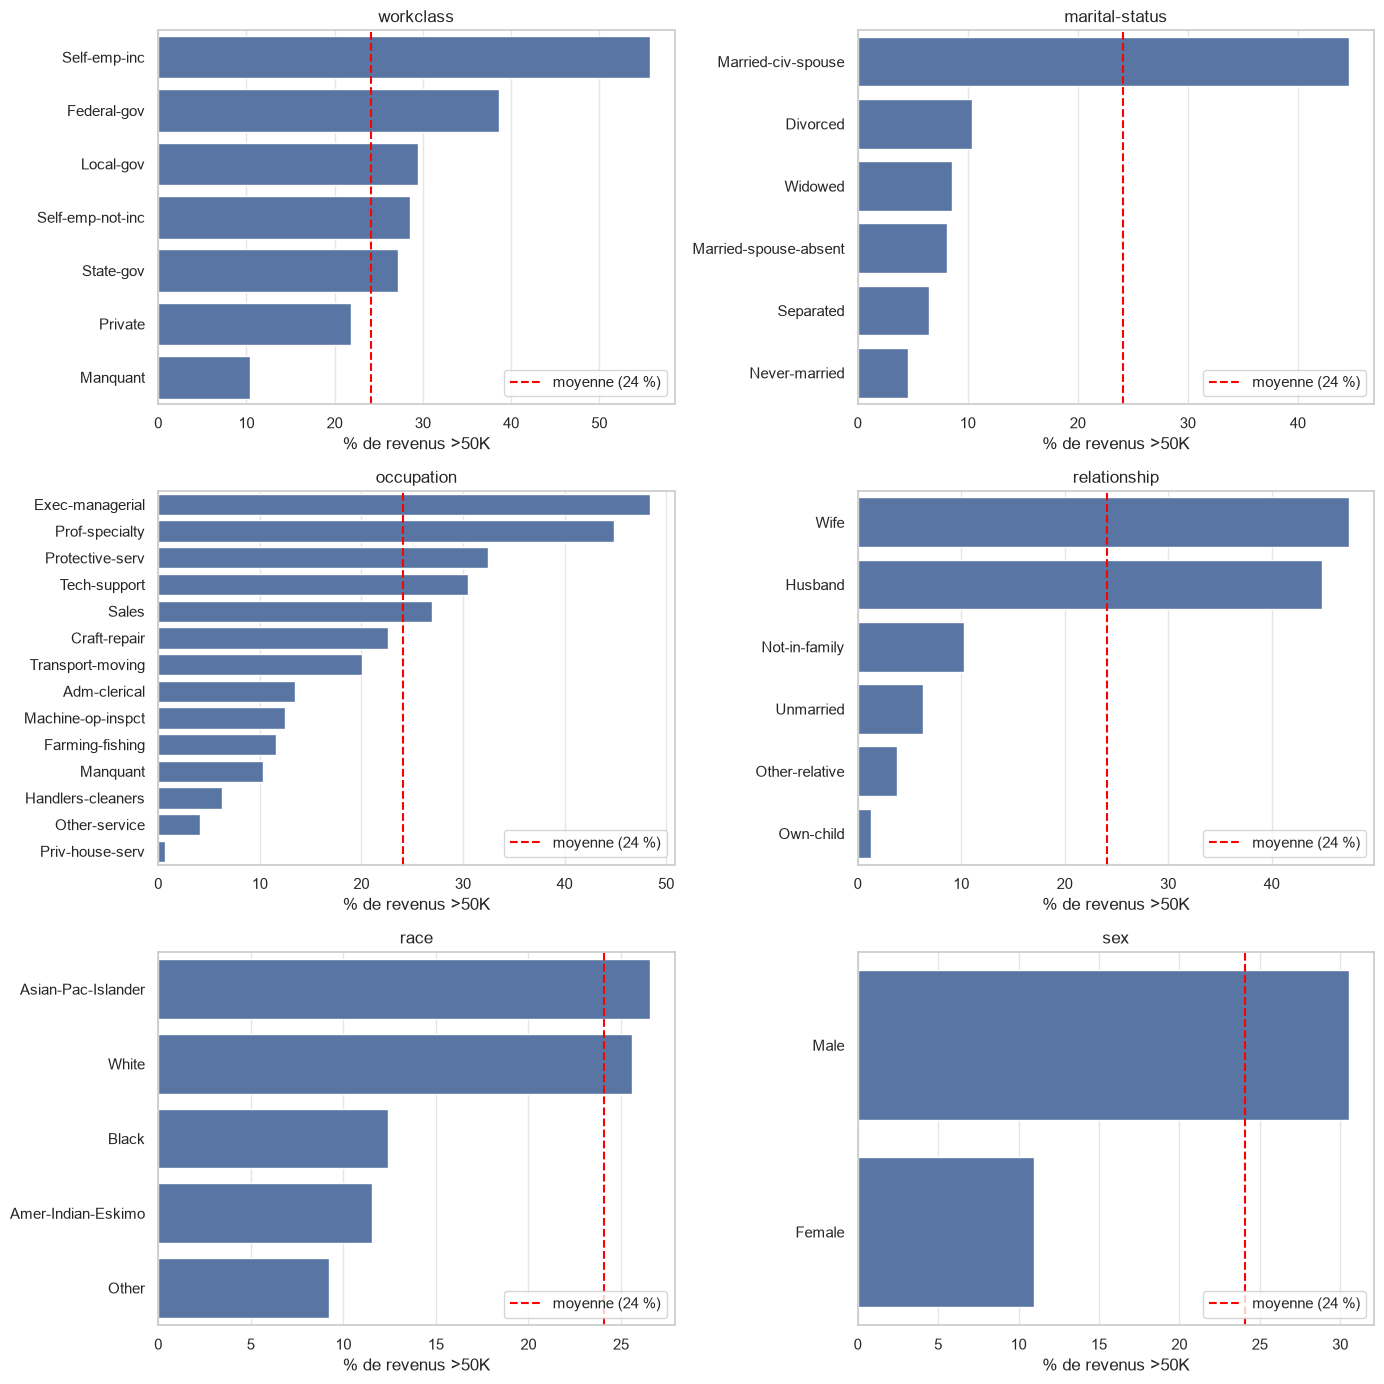

In [14]:
plot_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex"]
overall = 100 * y.mean()
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for ax, col in zip(axes.flat, plot_cols):
    rates = target_rate_by(train, col, y, min_count=30)
    sns.barplot(x=rates["taux_50k"], y=rates.index, ax=ax, color="#4C72B0")
    ax.axvline(overall, color="red", ls="--", label=f"moyenne ({overall:.0f} %)")
    ax.set(title=col, xlabel="% de revenus >50K", ylabel="")
    ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "eda_categorical_rates.png")

Nombre de valeurs education-num par niveau : 1


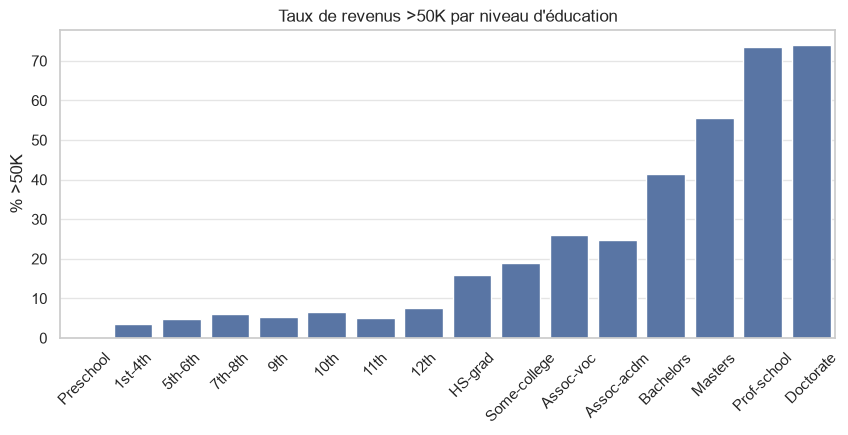

In [15]:
edu = target_rate_by(train, "education", y).join(
    train.groupby("education")["education-num"].first()).sort_values("education-num")
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=edu.index, y=edu["taux_50k"], ax=ax, color="#4C72B0")
ax.set(xlabel="", ylabel="% >50K", title="Taux de revenus >50K par niveau d'éducation")
ax.tick_params(axis="x", rotation=45)
save(fig, "eda_education.png")

# education et education-num : chaque niveau correspond-il à un seul nombre ?
print("Nombre de valeurs education-num par niveau :",
      train.groupby("education")["education-num"].nunique().max())

In [16]:
country = train["native-country"].value_counts(normalize=True).mul(100).round(2)
print(f"United-States : {country.get('United-States', 0)} % des lignes")
print(f"Pays représentant moins de 0,5 % des lignes : {(country < 0.5).sum()} sur {len(country)}")
country.head(10)

United-States : 91.22 % des lignes
Pays représentant moins de 0,5 % des lignes : 38 sur 41


native-country
United-States    91.22
Mexico            2.01
Philippines       0.62
Germany           0.43
Canada            0.38
Puerto-Rico       0.36
El-Salvador       0.33
India             0.31
Cuba              0.30
England           0.28
Name: proportion, dtype: float64

**À retenir** (vérifier sur vos sorties)
- `marital-status` / `relationship` : les personnes mariées (`Married-civ-spouse`, `Husband`,
  `Wife`) ont un taux de >50K bien supérieur aux autres. Ce sont parmi les variables les plus
  discriminantes.
- `occupation` : `Exec-managerial` et `Prof-specialty` en tête, les métiers manuels et de service en bas.
- `education` est **strictement redondante** avec `education-num` (un niveau = un nombre)
  → on garde seulement `education-num` (ordonnée, plus compacte).
- `native-country` : une très grande majorité de `United-States` et des dizaines de pays rares
  → regroupement des modalités rares (`min_frequency` du OneHotEncoder).
- `sex`, `race` : écarts de taux importants. Ce sont des **variables sensibles** : le modèle
  risque de reproduire ces inégalités. On analysera son équité à la fin (notebook 02).

relationship      0.453
marital-status    0.447
education         0.368
occupation        0.351
sex               0.216
workclass         0.179
race              0.100
native-country    0.092
Name: income, dtype: float64

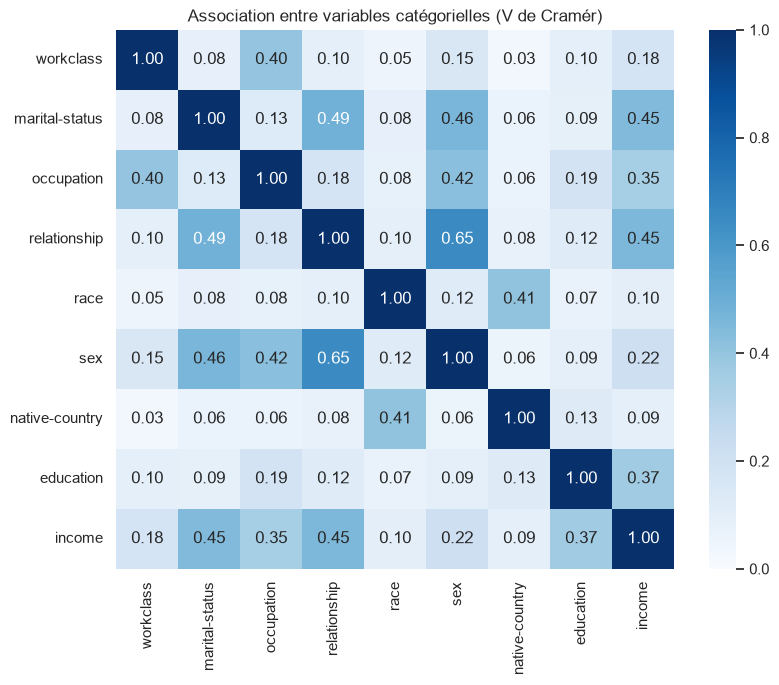

In [17]:
cramer = cramers_v_matrix(train, CAT + ["income"])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cramer, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Association entre variables catégorielles (V de Cramér)")
save(fig, "eda_cramers_v.png")
cramer["income"].drop("income").sort_values(ascending=False).round(3)

Le V de Cramér mesure l'association entre deux variables catégorielles (0 = aucune, 1 = parfaite).
- Les variables les plus liées à la cible sont `relationship` et `marital-status`.
- `relationship` et `marital-status` (ainsi que `sex` et `relationship`, via Husband/Wife)
  sont fortement associées entre elles : information en partie redondante. Pas gênant pour
  les modèles à base d'arbres ; la régularisation gère ce cas pour la régression logistique.

## 5. Synthèse : décisions de preprocessing

| Constat | Décision |
|---|---|
| Classes déséquilibrées (~76 / 24) | Métriques ROC-AUC, PR-AUC, F1 ; CV stratifiée ; baseline ; ajustement du seuil |
| Manquants dans 3 variables catégorielles | Imputation par la modalité la plus fréquente (dans le pipeline) |
| `capital-gain` / `capital-loss` très asymétriques | Transformation log(1+x) |
| `fnlwgt` = poids de sondage | Supprimée |
| `education` redondante avec `education-num` | Supprimée |
| `native-country` : beaucoup de pays rares | Regroupement des modalités < 0,5 % |
| Variables catégorielles | One-hot encoding |
| Échelles très différentes | Standardisation (indispensable pour KNN et régression logistique) |
| Relations non linéaires (âge, interactions) | Tester des modèles non linéaires (arbres, ensembles) |
| Variables sensibles (`sex`, `race`) | Analyse d'équité du modèle final |

Tout cela est implémenté dans `src/features/build_features.py`.
Suite : `02_modeling.ipynb`.